In [2]:
#Acá se va a hacer todo (o buena parte del) análisis de datos. La idea es extraerlos de la carpeta mediciones y trabajar ahí, después dejarlo en otros lados.

In [3]:
# Importación de librerías
# Importación de librerías esenciales para el análisis de datos de resonancia
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import signal

# Configuración para que los gráficos se muestren directamente en el notebook
%matplotlib inline

# Configuración básica opcional para mejorar la estética de los gráficos
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 12

print("¡Librerías importadas correctamente!")

¡Librerías importadas correctamente!


In [8]:
# Apertura del archivo. Esta celda recibe el nombre del archivo guardado en la carpeta Mediciones y guarda sus columnas en contenedores adecuados para trabajar con ellos. Cada archivo tiene la siguiente estructura de columnas:
# Frecuencia , X , Y , R

import os
import re
import pandas as pd

# Definir la carpeta y el nombre del archivo a cargar
carpeta = "Mediciones"
nombre_archivo = "26-10-1507.csv" # Reemplazá con tu archivo real
ruta_completa = os.path.join(carpeta, nombre_archivo)

# 1. Leer la primera línea para extraer el voltaje
with open(ruta_completa, 'r', encoding='latin-1') as f:
    primera_linea = f.readline().strip()

match = re.search(r"[-+]?\d*\.\d+|\d+", primera_linea)
if match:
    voltaje = float(match.group())
    print(f"Voltaje de excitación detectado: {voltaje} V")
else:
    print("No se pudo extraer el voltaje de la línea:", primera_linea)

# 2. Cargar los datos salteando la primera línea (skiprows=1)
datos = pd.read_csv(ruta_completa, skiprows=1, encoding='latin-1')

# Limpiar posibles espacios extra en los nombres de las columnas
datos.columns = datos.columns.str.strip()

# Imprimir las columnas detectadas para verificar
print("Columnas detectadas:", datos.columns.tolist())

# Extraer las columnas usando los nombres exactos del archivo
frecuencia = datos['Frecuencia (Hz)'].values
X = datos['X (V)'].values
Y = datos['Y (V)'].values
R = datos['R (V)'].values

# Mostrar un resumen rápido para verificar
print(f"Archivo cargado exitosamente: {nombre_archivo}")
print(f"Cantidad de puntos en el barrido: {len(frecuencia)}")
print(f"Rango de frecuencias: de {frecuencia[0]:.2f} Hz a {frecuencia[-1]:.2f} Hz")

Voltaje de excitación detectado: 0.1 V
Columnas detectadas: ['Frecuencia (Hz)', 'X (V)', 'Y (V)', 'R (V)']
Archivo cargado exitosamente: 26-10-1507.csv
Cantidad de puntos en el barrido: 450
Rango de frecuencias: de 63500.00 Hz a 68000.00 Hz


In [ ]:
# Análisis Amplitud vs Frecuencia

# Tiene que recibir un archivo de datos de un barrido. Hallar el fondo, restárselo y graficar amplitud vs frecuencia. Tiene que identificar la frecuencia de resonancia y guardarla en un lugar emparejada con la amplitud para después hacer el gráfico frecuencia de pico vs amplitud.  

¡Detección automática completada!
  -> Frecuencia de inicio detectada: 64893.10 Hz
  -> Frecuencia de fin detectada:   66546.77 Hz


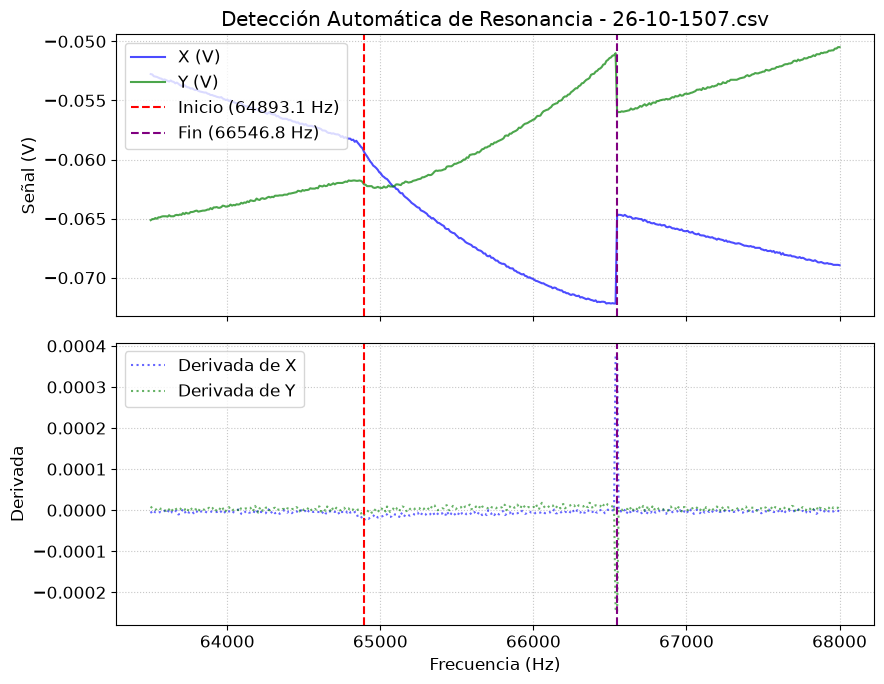

In [12]:
# Hallado del fondo
# Este bloque encuentra las frecuencias de inicio y fin de la resonancia. 

# Busca el inicio mediante cambios notables en la derivada de X e Y,
# y el fin detectando el salto discreto característico.

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# PARÁMETROS DE CONFIGURACIÓN Y CONTROL
# ==========================================
# Booleano para activar o desactivar el gráfico de control de la detección
mostrar_grafico_deteccion = True

# Parámetros de sensibilidad (pueden ajustarse si el tren de archivos varía un poco)
# 1. Umbral para la derivada (inicio del fenómeno)
# 2. Umbral para el salto discreto en la derivada o diferencia (fin del fenómeno)
# ==========================================

# Calcular la derivada numérica de X e Y respecto a la frecuencia (o índice de puntos)
# Usamos np.gradient
derivada_X = np.gradient(X, frecuencia)
derivada_Y = np.gradient(Y, frecuencia)

# Una forma robusta de detectar el cambio brusco al inicio es buscar donde 
# la magnitud de la derivada o la aceleración (segunda derivada) supera un umbral estadístico,
# o donde se desvía fuertemente del comportamiento plano del fondo.
# Aquí proponemos un enfoque basado en desviación estándar o picos en la derivada:

# Criterio para el INICIO: 
# Buscamos el primer punto donde la derivada de X o Y supera un cierto nivel de ruido del fondo.
# Por ejemplo, detectamos el punto donde el valor absoluto de la derivada supera 
# un umbral basado en la mediana de la derivada de la zona inicial.
ruido_fondo_X = np.median(np.abs(derivada_X[:int(len(frecuencia)*0.1)])) # miramos el inicio del barrido
umbral_inicio = max(5.0 * ruido_fondo_X, 1e-6)

# Encontramos los índices donde se supera el umbral de derivada
indices_inicio_candidatos = np.where((np.abs(derivada_X) > umbral_inicio) | (np.abs(derivada_Y) > umbral_inicio))[0]

if len(indices_inicio_candidatos) > 0:
    # Tomamos el primer punto sostenido donde ocurre
    idx_inicio = indices_inicio_candidatos[0]
    f_inicio = frecuencia[idx_inicio]
else:
    # Plan B por seguridad si no lo detecta automáticamente
    idx_inicio = int(len(frecuencia) * 0.3)
    f_inicio = frecuencia[idx_inicio]

# Criterio para el FIN:
# Al final del fenómeno hay un salto discreto apreciable en X e Y. 
# Un salto brusco se manifiesta como un pico agudo y aislado en la derivada (una discontinuidad).
# Buscamos el punto de máxima derivada o un cambio abrupto posterior al inicio.
indices_posteriores = np.where(frecuencia > f_inicio)[0]
if len(indices_posteriores) > 0:
    # Buscamos el punto con el cambio más abrupto (máximo absoluto de la derivada combinada o diferencia)
    derivada_combinada = np.abs(derivada_X[indices_posteriores]) + np.abs(derivada_Y[indices_posteriores])
    idx_salto_relativo = np.argmax(derivada_combinada)
    idx_fin = indices_posteriores[idx_salto_relativo]
    f_fin = frecuencia[idx_fin]
else:
    idx_fin = int(len(frecuencia) * 0.7)
    f_fin = frecuencia[idx_fin]

print(f"¡Detección automática completada!")
print(f"  -> Frecuencia de inicio detectada: {f_inicio:.2f} Hz")
print(f"  -> Frecuencia de fin detectada:   {f_fin:.2f} Hz")

# Gráfico de control opcional
if mostrar_grafico_deteccion:
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    
    # Gráfico superior: Señales X e Y originales
    ax1.plot(frecuencia, X, 'b-', label='X (V)', alpha=0.7)
    ax1.plot(frecuencia, Y, 'g-', label='Y (V)', alpha=0.7)
    ax1.axvline(f_inicio, color='red', linestyle='--', label=f'Inicio ({f_inicio:.1f} Hz)')
    ax1.axvline(f_fin, color='purple', linestyle='--', label=f'Fin ({f_fin:.1f} Hz)')
    ax1.set_ylabel('Señal (V)')
    ax1.set_title(f'Detección Automática de Resonancia - {nombre_archivo}')
    ax1.legend(loc='upper left')
    ax1.grid(True, linestyle=':', alpha=0.7)
    
    # Gráfico inferior: Derivadas (para visualizar dónde ocurren los cambios y saltos)
    ax2.plot(frecuencia, derivada_X, 'b:', label="Derivada de X", alpha=0.6)
    ax2.plot(frecuencia, derivada_Y, 'g:', label="Derivada de Y", alpha=0.6)
    ax2.axvline(f_inicio, color='red', linestyle='--')
    ax2.axvline(f_fin, color='purple', linestyle='--')
    ax2.set_xlabel('Frecuencia (Hz)')
    ax2.set_ylabel('Derivada')
    ax2.legend(loc='upper left')
    ax2.grid(True, linestyle=':', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

Límite de inicio ajustado: 64792.87 Hz (retrocedimos 10 puntos)
Límite de fin mantenido:    66546.77 Hz
¡Coeficientes calculados y fondos estimados para X e Y con éxito!
  -> Coeficientes X: [ 4.12881491e-18 -1.07832527e-12  1.05759065e-07 -4.62026884e-03
  7.58595855e+01]
  -> Coeficientes Y: [ 7.74089188e-18 -2.05037347e-12  2.03809652e-07 -9.00712073e-03
  1.49209962e+02]


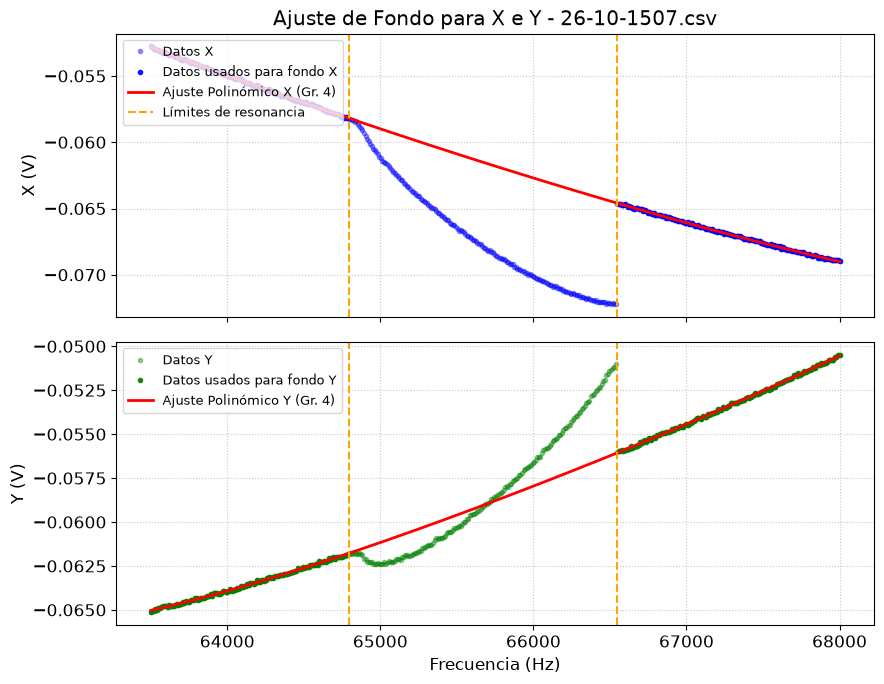

In [14]:
# Hallado del fondo
# La idea sería tomar los datos medidos antes y después del pico y ajustarlos con un polinomio. Lo que tiene que hacer la celda es dar los coeficientes del polinomio. Estaría bueno que grafique los datos y el polinomio para ver si el ajuste es bueno, la generación de este gráfico tiene que poder activarse y desactivarse.

# Ajuste del fondo para X e Y: cálculo de coeficientes polinómicos
# (Utiliza los límites detectados en la celda anterior, ajustando el inicio 10 puntos antes)

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# PARÁMETROS DE CONFIGURACIÓN Y CONTROL
# ==========================================
# Booleano para activar o desactivar el gráfico de control del ajuste del fondo
mostrar_grafico_fondo_xy = True

# Cantidad de puntos a retroceder para asegurar un inicio limpio fuera de la resonancia
puntos_margen_inicio = 10
# ==========================================

# 1. Encontrar el índice donde estaba el f_inicio preliminar y retroceder
idx_inicio_preliminar = np.argmin(np.abs(frecuencia - f_inicio))
idx_inicio_corregido = max(0, idx_inicio_preliminar - puntos_margen_inicio)
f_inicio_real = frecuencia[idx_inicio_corregido]

# El índice de fin ya funciona bien, lo mantenemos
idx_fin_real = np.argmin(np.abs(frecuencia - f_fin))
f_fin_real = f_fin

print(f"Límite de inicio ajustado: {f_inicio_real:.2f} Hz (retrocedimos {puntos_margen_inicio} puntos)")
print(f"Límite de fin mantenido:    {f_fin_real:.2f} Hz")

# 2. Definir la máscara para los puntos del fondo (fuera de la resonancia)
mask_fondo = (frecuencia < f_inicio_real) | (frecuencia > f_fin_real)

freq_fondo = frecuencia[mask_fondo]
X_fondo = X[mask_fondo]
Y_fondo = Y[mask_fondo]

# 3. Ajustar polinomios de grado 4 por separado para X e Y
coefs_X = np.polyfit(freq_fondo, X_fondo, deg=4)
coefs_Y = np.polyfit(freq_fondo, Y_fondo, deg=4)

# 4. Estimar el fondo para todo el rango de frecuencias
fondo_X = np.polyval(coefs_X, frecuencia)
fondo_Y = np.polyval(coefs_Y, frecuencia)

print("¡Coeficientes calculados y fondos estimados para X e Y con éxito!")
print("  -> Coeficientes X:", coefs_X)
print("  -> Coeficientes Y:", coefs_Y)

# Gráfico de control opcional para verificar el ajuste del fondo en X e Y
if mostrar_grafico_fondo_xy:
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    
    # Panel para X
    ax1.plot(frecuencia, X, 'b.', alpha=0.4, label='Datos X')
    ax1.plot(freq_fondo, X_fondo, 'b.', alpha=0.9, label='Datos usados para fondo X')
    ax1.plot(frecuencia, fondo_X, 'r-', linewidth=2, label='Ajuste Polinómico X (Gr. 4)')
    ax1.axvline(f_inicio_real, color='orange', linestyle='--', label='Límites de resonancia')
    ax1.axvline(f_fin_real, color='orange', linestyle='--')
    ax1.set_ylabel('X (V)')
    ax1.set_title(f'Ajuste de Fondo para X e Y - {nombre_archivo}')
    ax1.legend(loc='upper left', fontsize=9)
    ax1.grid(True, linestyle=':', alpha=0.7)
    
    # Panel para Y
    ax2.plot(frecuencia, Y, 'g.', alpha=0.4, label='Datos Y')
    ax2.plot(freq_fondo, Y_fondo, 'g.', alpha=0.9, label='Datos usados para fondo Y')
    ax2.plot(frecuencia, fondo_Y, 'r-', linewidth=2, label='Ajuste Polinómico Y (Gr. 4)')
    ax2.axvline(f_inicio_real, color='orange', linestyle='--')
    ax2.axvline(f_fin_real, color='orange', linestyle='--')
    ax2.set_xlabel('Frecuencia (Hz)')
    ax2.set_ylabel('Y (V)')
    ax2.legend(loc='upper left', fontsize=9)
    ax2.grid(True, linestyle=':', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

In [17]:
# Preparación de datos amplitud vs frecuencia. Esta celda resta el fondo a los datos originales y deja los datos listos para graficar. Estos se guardarían en una carpeta llamada Mediciones_sin_fondo, a cada archivo se lo llama igual y al final del nombre dice _SF. Primero corrige X e Y, calcula un R corregido y arma un archivo de datos igual al original pero poniendo en las columnas de X, Y  y R los datos corregidos.

# Preparación de datos amplitud vs frecuencia (con columna de Fase).
# Resta el fondo a X e Y, calcula R, calcula la Fase corregida (arctan2(Y/X)),
# y guarda los datos en 'Mediciones_sin_fondo' con el sufijo '_SF'.

import os
import numpy as np

# 1. Definir la carpeta de salida y crearla si no existe
carpeta_salida = "Mediciones_sin_fondo"
os.makedirs(carpeta_salida, exist_ok=True)

# 2. Calcular los fondos evaluando los coeficientes en todo el rango de frecuencias
fondo_X = np.polyval(coefs_X, frecuencia)
fondo_Y = np.polyval(coefs_Y, frecuencia)

# 3. Restar el fondo a X e Y, calcular R corregido y calcular la Fase corregida
X_corregido = X - fondo_X
Y_corregido = Y - fondo_Y
R_corregido = np.sqrt(X_corregido**2 + Y_corregido**2)

# Usamos np.arctan2(Y, X) para obtener la fase en radianes abarcando todo el círculo trigonométrico
fase_corregida = np.arctan2(Y_corregido, X_corregido)

# 4. Armar el nombre del archivo de salida
base_nombre, ext = os.path.splitext(nombre_archivo)
nombre_archivo_sf = f"{base_nombre}_SF{ext}"
ruta_salida = os.path.join(carpeta_salida, nombre_archivo_sf)

# 5. Escribir el nuevo archivo incluyendo la columna 'Fase (rad)'
with open(ruta_completa, 'r', encoding='latin-1') as f:
    primera_linea = f.readline().strip()

with open(ruta_salida, 'w', encoding='latin-1') as f_out:
    # Escribir la primera línea (Voltaje)
    f_out.write(f"{primera_linea}\n")
    
    # Escribir la cabecera con la nueva columna de fase
    f_out.write("Frecuencia (Hz),X (V),Y (V),R (V),Fase (rad)\n")
    
    # Escribir cada fila de datos corregidos
    for f_val, x_val, y_val, r_val, phi_val in zip(frecuencia, X_corregido, Y_corregido, R_corregido, fase_corregida):
        f_out.write(f"{f_val},{x_val},{y_val},{r_val},{phi_val}\n")

print(f"¡Datos corregidos y columna de Fase guardados exitosamente!")
print(f"  -> Archivo de salida: {ruta_salida}")


¡Datos corregidos y columna de Fase guardados exitosamente!
  -> Archivo de salida: Mediciones_sin_fondo\26-10-1507_SF.csv


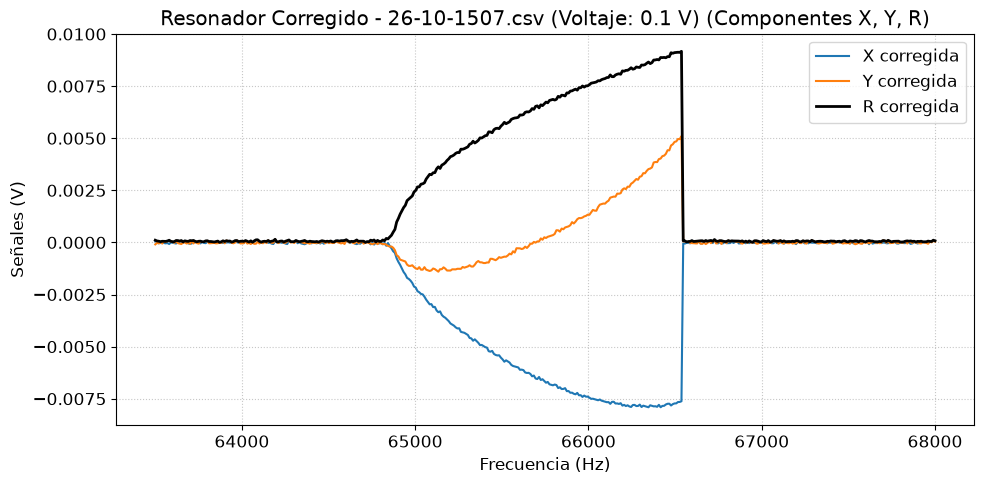

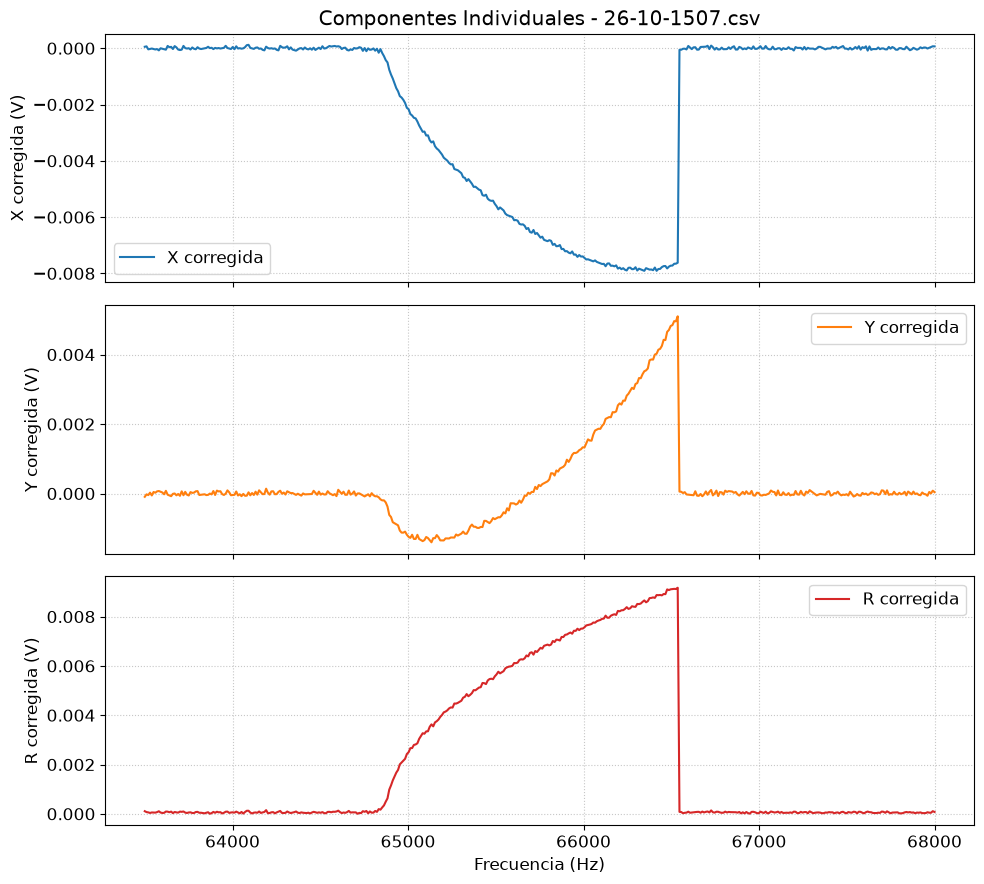

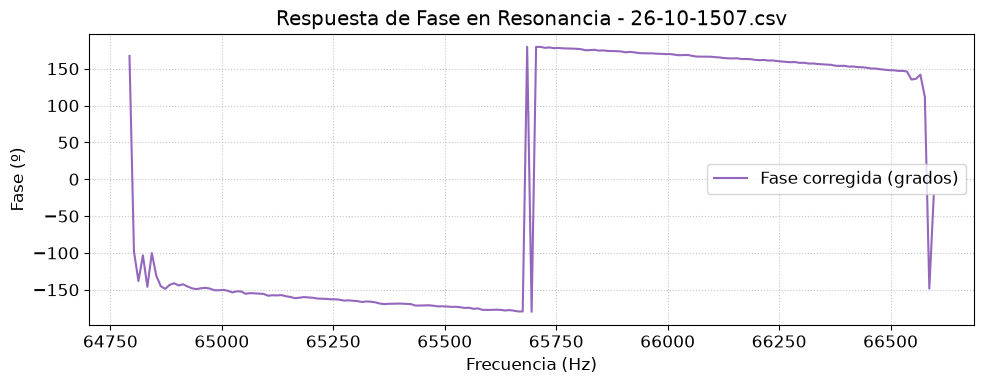

In [20]:
# Gráficos de las señales corregidas (X, Y, R y Fase) en función de la frecuencia
# Permite personalizar visualizaciones, escalas, marcadores y leyendas.

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# PARÁMETROS DE CONFIGURACIÓN DEL GRÁFICO
# ==========================================
# Opciones de visualización de puntos/líneas:
# - 'line': une los puntos con una línea continua
# - 'marker': dibuja solo símbolos en cada punto sin unirlos
# - 'both': dibuja la línea y los símbolos en cada punto
estilo_trazo = 'line'  
marcador = '.'         
ancho_linea = 1.5      
tamanio_marker = 6     

# Personalización de títulos, escalas y leyendas
titulo_principal = f"Resonador Corregido - {nombre_archivo} (Voltaje: {voltaje} V)"
posicion_leyenda = 'best'  
escala_y = 'linear'       # 'linear' o 'log' para X, Y, R
mostrar_grilla = True

# Opcional para la Fase: si preferís verla en grados en lugar de radianes, cambialo a True
convertir_fase_a_grados = True 
# ==========================================

# Asegurar que la fase esté calculada en memoria por si se ejecuta esta celda sola
if 'fase_corregida' not in locals():
    fondo_X = np.polyval(coefs_X, frecuencia)
    fondo_Y = np.polyval(coefs_Y, frecuencia)
    X_corr_temp = X - fondo_X
    Y_corr_temp = Y - fondo_Y
    fase_corregida = np.arctan2(Y_corr_temp, X_corr_temp)

# Definir estilo de trazado
if estilo_trazo == 'line':
    linestyle, marker_style = '-', 'None'
elif estilo_trazo == 'marker':
    linestyle, marker_style = 'None', marcador
else: 
    linestyle, marker_style = '-', marcador

# ------------------------------------------
# 1. GRÁFICO CONJUNTO (X, Y y R en simultáneo)
# ------------------------------------------
plt.figure(figsize=(10, 5))
plt.plot(frecuencia, X_corregido, label='X corregida', linestyle=linestyle, marker=marker_style, linewidth=ancho_linea, markersize=tamanio_marker)
plt.plot(frecuencia, Y_corregido, label='Y corregida', linestyle=linestyle, marker=marker_style, linewidth=ancho_linea, markersize=tamanio_marker)
plt.plot(frecuencia, R_corregido, label='R corregida', linestyle=linestyle, marker=marker_style, linewidth=ancho_linea+0.5, markersize=tamanio_marker, color='black')

plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Señales (V)')
plt.title(titulo_principal + " (Componentes X, Y, R)")
plt.yscale(escala_y)
plt.legend(loc=posicion_leyenda)
plt.grid(mostrar_grilla, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# ------------------------------------------
# 2. GRÁFICOS INDIVIDUALES (Panel vertical para X, Y, R)
# ------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(frecuencia, X_corregido, label='X corregida', linestyle=linestyle, marker=marker_style, linewidth=ancho_linea, markersize=tamanio_marker, color='tab:blue')
axes[0].set_ylabel('X corregida (V)')
axes[0].set_title(f"Componentes Individuales - {nombre_archivo}")
axes[0].legend(loc=posicion_leyenda)
axes[0].grid(mostrar_grilla, linestyle=':', alpha=0.7)
axes[0].set_yscale(escala_y)

axes[1].plot(frecuencia, Y_corregido, label='Y corregida', linestyle=linestyle, marker=marker_style, linewidth=ancho_linea, markersize=tamanio_marker, color='tab:orange')
axes[1].set_ylabel('Y corregida (V)')
axes[1].legend(loc=posicion_leyenda)
axes[1].grid(mostrar_grilla, linestyle=':', alpha=0.7)
axes[1].set_yscale(escala_y)

axes[2].plot(frecuencia, R_corregido, label='R corregida', linestyle=linestyle, marker=marker_style, linewidth=ancho_linea, markersize=tamanio_marker, color='tab:red')
axes[2].set_xlabel('Frecuencia (Hz)')
axes[2].set_ylabel('R corregida (V)')
axes[2].legend(loc=posicion_leyenda)
axes[2].grid(mostrar_grilla, linestyle=':', alpha=0.7)
axes[2].set_yscale(escala_y)

plt.tight_layout()
plt.show()

# ------------------------------------------
# GRÁFICO SEPARADO PARA LA FASE (Filtrado en la zona de resonancia)
# ------------------------------------------

# 1. Definir la máscara para recortar el gráfico: desde f_inicio_real hasta 5 puntos después de f_fin_real
idx_inicio_plot = np.argmin(np.abs(frecuencia - f_inicio_real))
idx_fin_preliminar_plot = np.argmin(np.abs(frecuencia - f_fin_real))
idx_fin_plot = min(len(frecuencia) - 1, idx_fin_preliminar_plot + 5)

mask_fase_plot = (np.arange(len(frecuencia)) >= idx_inicio_plot) & (np.arange(len(frecuencia)) <= idx_fin_plot)

freq_fase_plot = frecuencia[mask_fase_plot]
fase_plot = fase_corregida[mask_fase_plot]

# 2. Configuración y ploteo
plt.figure(figsize=(10, 4))
if convertir_fase_a_grados:
    datos_fase = np.degrees(fase_plot)
    label_fase = 'Fase corregida (grados)'
    ylabel_fase = 'Fase (º)'
else:
    datos_fase = fase_plot
    label_fase = 'Fase corregida (radianes)'
    ylabel_fase = 'Fase (rad)'

plt.plot(freq_fase_plot, datos_fase, label=label_fase, linestyle=linestyle, marker=marker_style, linewidth=ancho_linea, markersize=tamanio_marker, color='tab:purple')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel(ylabel_fase)
plt.title(f"Respuesta de Fase en Resonancia - {nombre_archivo}")
plt.legend(loc=posicion_leyenda)
plt.grid(mostrar_grilla, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Automatización en lote con contenedores en Arrays de NumPy
import os
import re
import numpy as np

# ==========================================
# PARÁMETROS DE CONFIGURACIÓN DEL LOTE
# ==========================================
carpeta_entrada = "Mediciones"
carpeta_salida = "Mediciones_sin_fondo"
os.makedirs(carpeta_salida, exist_ok=True)

puntos_margen_inicio = 10

# Contenedores en listas de Python (que luego convertiremos a arrays de NumPy)
lista_voltajes = []
lista_f_fin = []
lista_archivos = []
# ==========================================

archivos = [f for f in os.listdir(carpeta_entrada) if f.endswith('.csv')]
print(f"Se encontraron {len(archivos)} archivos para procesar.\n" + "-"*50)

for nombre_archivo in archivos:
    ruta_completa = os.path.join(carpeta_entrada, nombre_archivo)
    
    # 1. Leer la primera línea para extraer el voltaje
    with open(ruta_completa, 'r', encoding='latin-1') as f:
        primera_linea = f.readline().strip()

    match = re.search(r"[-+]?\d*\.\d+|\d+", primera_linea)
    voltaje = float(match.group()) if match else np.nan

    # 2. Cargar los datos del barrido
    # Usamos np.loadtxt o genfromtxt, o seguimos con pandas solo para leer la tabla numérica de forma rápida y limpia
    import pandas as pd
    datos = pd.read_csv(ruta_completa, skiprows=1, encoding='latin-1')
    datos.columns = datos.columns.str.strip()

    frecuencia = datos['Frecuencia (Hz)'].values
    X = datos['X (V)'].values
    Y = datos['Y (V)'].values
    R = datos['R (V)'].values

    # 3. Detección automática de inicio y fin
    derivada_X = np.gradient(X, frecuencia)
    derivada_Y = np.gradient(Y, frecuencia)

    ruido_fondo_X = np.median(np.abs(derivada_X[:int(len(frecuencia)*0.1)]))
    umbral_inicio = max(5.0 * ruido_fondo_X, 1e-6)

    indices_inicio_candidatos = np.where((np.abs(derivada_X) > umbral_inicio) | (np.abs(derivada_Y) > umbral_inicio))[0]
    idx_inicio_prel = indices_inicio_candidatos[0] if len(indices_inicio_candidatos) > 0 else int(len(frecuencia) * 0.3)
    f_inicio_preliminar = frecuencia[idx_inicio_prel]

    indices_posteriores = np.where(frecuencia > f_inicio_preliminar)[0]
    if len(indices_posteriores) > 0:
        derivada_combinada = np.abs(derivada_X[indices_posteriores]) + np.abs(derivada_Y[indices_posteriores])
        idx_fin = indices_posteriores[np.argmax(derivada_combinada)]
        f_fin = frecuencia[idx_fin]
    else:
        idx_fin = int(len(frecuencia) * 0.7)
        f_fin = frecuencia[idx_fin]

    # 4. Margen de seguridad al inicio
    idx_inicio_real_pos = max(0, idx_inicio_prel - puntos_margen_inicio)
    f_inicio_real = frecuencia[idx_inicio_real_pos]
    f_fin_real = f_fin

    # 5. Ajuste de fondo con polinomios de grado 4
    mask_fondo = (frecuencia < f_inicio_real) | (frecuencia > f_fin_real)
    freq_fondo = frecuencia[mask_fondo]
    X_fondo = X[mask_fondo]
    Y_fondo = Y[mask_fondo]

    coefs_X = np.polyfit(freq_fondo, X_fondo, deg=4)
    coefs_Y = np.polyfit(freq_fondo, Y_fondo, deg=4)

    fondo_X = np.polyval(coefs_X, frecuencia)
    fondo_Y = np.polyval(coefs_Y, frecuencia)

    # 6. Corrección y cálculo de R y Fase
    X_corregido = X - fondo_X
    Y_corregido = Y - fondo_Y
    R_corregido = np.sqrt(X_corregido**2 + Y_corregido**2)
    fase_corregida = np.arctan2(Y_corregido, X_corregido)

    # 7. Guardar el archivo '_SF'
    base_nombre, ext = os.path.splitext(nombre_archivo)
    nombre_archivo_sf = f"{base_nombre}_SF{ext}"
    ruta_salida = os.path.join(carpeta_salida, nombre_archivo_sf)

    with open(ruta_salida, 'w', encoding='latin-1') as f_out:
        f_out.write(f"{primera_linea}\n")
        f_out.write("Frecuencia (Hz),X (V),Y (V),R (V),Fase (rad)\n")
        for f_val, x_val, y_val, r_val, phi_val in zip(frecuencia, X_corregido, Y_corregido, R_corregido, fase_corregida):
            f_out.write(f"{f_val},{x_val},{y_val},{r_val},{phi_val}\n")

    # 8. Guardar en contenedores tipo lista para pasarlos a arrays de NumPy
    lista_archivos.append(nombre_archivo)
    lista_voltajes.append(voltaje)
    lista_f_fin.append(f_fin_real)

    print(f"[OK] {nombre_archivo} | Voltaje: {voltaje} V | f_fin: {f_fin_real:.2f} Hz")

# ==========================================
# CONVERSIÓN A ARRAYS DE NUMPY AL FINAL
# ==========================================
voltajes_array = np.array(lista_voltajes)
f_fin_array = np.array(lista_f_fin)
archivos_array = np.array(lista_archivos)

print("-" * 50)
print("¡Procesamiento en lote completado!")
print(f"Array de Voltajes creado: {voltajes_array}")
print(f"Array de Frecuencias f_fin creado: {f_fin_array}")

In [ ]:
# Gráfica amplitud vs frecuencia de pico. En esta celda se grafican los datos de amplitud vs frecuencia de pioo generados en la anterior. La idea es poder ajustar parámetros del gráfico como escalas, colores y leyendas.